# Hotel Booking Cancellation Prediction – full code (Stages 1–7)
Run each cell in order with ▶, or **Runtime → Run all** (about 5 minutes).
The dataset loads by itself: from the Files panel if you uploaded `hotel_bookings.csv`, otherwise it downloads from GitHub.

In [1]:
# Hotel Booking Cancellation Prediction
# Part 1 – Business Understanding (Chapter 2)
# Part 2 – Data Understanding (Chapter 3)
# 2.1 Collect initial data – import libraries and load the file
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2b6cb0", "#dd6b20", "#a0aec0"
print("Libraries loaded")

Libraries loaded


In [2]:
# Load the dataset. No upload needed: if the file is not in the Files panel or the repo folder,
# it is downloaded from the GitHub repository automatically.
import os
GITHUB_CSV = "https://raw.githubusercontent.com/ixanm10/hotel-cancellation-prediction/main/data/hotel_bookings.csv"
candidates = ["hotel_bookings.csv", "data/hotel_bookings.csv", "../data/hotel_bookings.csv", "/content/hotel_bookings.csv"]
FILE_PATH = next((p for p in candidates if os.path.exists(p)), GITHUB_CSV)

raw = pd.read_csv(FILE_PATH)
print("Loaded:", FILE_PATH, "| Rows:", raw.shape[0], "| Columns:", raw.shape[1])
assert raw.shape[0] == 119390, "The dataset is incomplete - check the file and run again"

Loaded: data/hotel_bookings.csv | Rows: 119390 | Columns: 32


In [3]:
# 2.2 Describe data – size, columns and types
raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
# Types of data (Chapter 3: nominal, ordinal, interval, ratio)
nominal = raw.select_dtypes(exclude="number").columns.tolist()
numeric = raw.select_dtypes(include="number").columns.tolist()
print(len(nominal), "text/nominal columns:", nominal)
print()
print(len(numeric), "numeric columns:", numeric)

12 text/nominal columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

20 numeric columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [6]:
# 2.3 Explore data – descriptive statistics
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [7]:
# Categorical columns: number of different values and the most frequent value (mode)
raw.describe(include="object").T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    63.0 %
1    37.0 %
Name: proportion, dtype: str


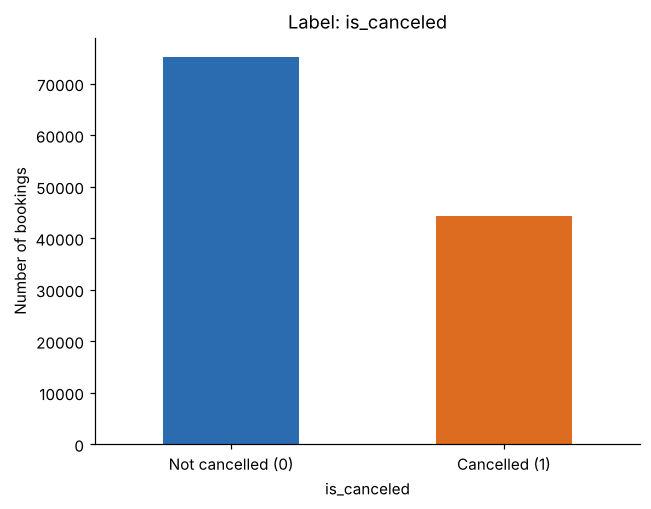

In [8]:
print(raw["is_canceled"].value_counts())
print((raw["is_canceled"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

raw["is_canceled"].value_counts().plot(kind="bar", color=[BLUE, ORANGE])
plt.xticks([0, 1], ["Not cancelled (0)", "Cancelled (1)"], rotation=0)
plt.title("Label: is_canceled"); plt.ylabel("Number of bookings"); plt.show()

In [9]:
# 2.4 Verify data quality
# 1. Missing values per column
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(2)})

,missing,percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [10]:
# 2-5. Noise, inconsistencies, redundancy, incorrect types
guests_raw = raw["adults"] + raw["children"].fillna(0) + raw["babies"]
nights_raw = raw["stays_in_weekend_nights"] + raw["stays_in_week_nights"]

quality = {
    "1. Missing cells (total)":               int(raw.isna().sum().sum()),
    "2. Noise: bookings with 0 guests":       int((guests_raw == 0).sum()),
    "2. Noise: bookings with 0 nights":       int((nights_raw == 0).sum()),
    "2. Noise: negative price (adr < 0)":     int((raw["adr"] < 0).sum()),
    "2. Noise: extreme price (adr > 1000)":   int((raw["adr"] > 1000).sum()),
    "3. Inconsistent: meal = 'Undefined'":    int((raw["meal"] == "Undefined").sum()),
    "3. Inconsistent: segment = 'Undefined'": int((raw["market_segment"] == "Undefined").sum()),
    "3. Inconsistent: channel = 'Undefined'": int((raw["distribution_channel"] == "Undefined").sum()),
    "4. Redundancy: duplicate rows":          int(raw.duplicated().sum()),
    "5. Incorrect type: month stored as text":  raw["arrival_date_month"].dtype == object or str(raw["arrival_date_month"].dtype) == "str",
    "5. Incorrect type: date stored as text":   raw["reservation_status_date"].dtype == object or str(raw["reservation_status_date"].dtype) == "str",
    "5. Incorrect type: children is float":    str(raw["children"].dtype),
}
pd.Series(quality, name="result").to_frame()

,result
1. Missing cells (total),129425
2. Noise: bookings with 0 guests,180
2. Noise: bookings with 0 nights,715
2. Noise: negative price (adr < 0),1
2. Noise: extreme price (adr > 1000),1
3. Inconsistent: meal = 'Undefined',1169
3. Inconsistent: segment = 'Undefined',2
3. Inconsistent: channel = 'Undefined',5
4. Redundancy: duplicate rows,31994
5. Incorrect type: month stored as text,True


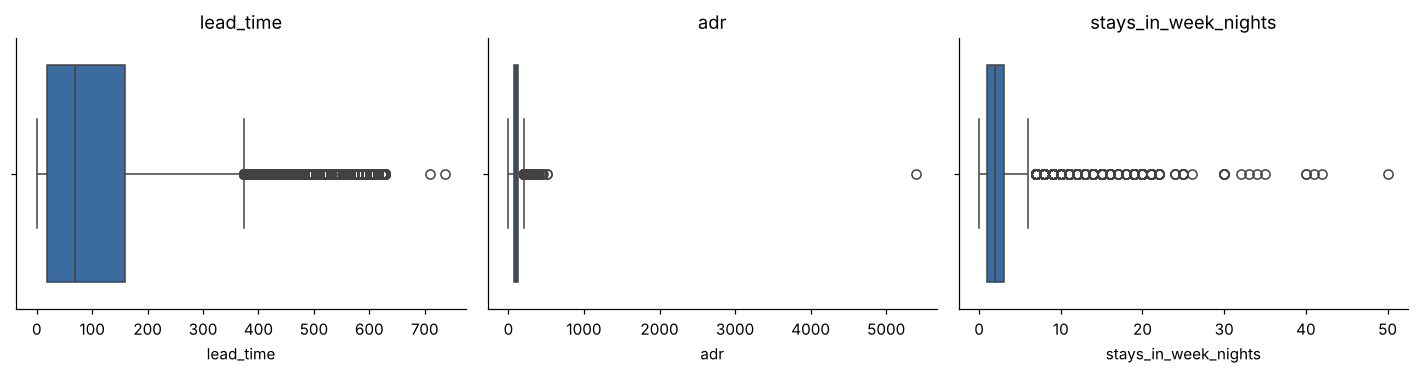

In [11]:
# Boxplots to SEE outliers in key numeric columns
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["lead_time", "adr", "stays_in_week_nights"]):
    sns.boxplot(x=raw[col], ax=ax, color=BLUE)
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [12]:
# Part 3 – Data Preparation (Chapter 4)
df = raw.copy()
log = []          # Step 7: documentation log – every action is recorded here
def record(step, action, reason, rows_affected=""):
    log.append({"step": step, "action": action, "reason": reason, "rows/cols affected": rows_affected})

In [13]:
# Step 1 – Select relevant attributes
# Variance check (like 'Remove Useless Attributes'): share of the most common value in each column
dominant = raw.apply(lambda c: c.value_counts(normalize=True, dropna=False).iloc[0]).sort_values(ascending=False)
print("Share of the most frequent value (top 6):")
print((dominant.head(6) * 100).round(1).astype(str) + " %")

Share of the most frequent value (top 6):
babies                            99.2 %
previous_bookings_not_canceled    97.0 %
days_in_waiting_list              96.9 %
is_repeated_guest                 96.8 %
previous_cancellations            94.6 %
company                           94.3 %
dtype: str


In [14]:
df = df.drop(columns=["company"])
record(1, "Dropped column company", "94% missing values – almost empty", "1 column")
record(1, "Excluded reservation_status, reservation_status_date, assigned_room_type from modelling",
       "Data leakage – only known after the booking outcome", "3 columns")
print("Columns now:", df.shape[1])

Columns now: 31


In [15]:
# Step 2 – Clean data
# 2a. Missing values – choosing the right imputation method (slides 36–43)
print("children mode:", df["children"].mode()[0], "| median:", df["children"].median())

df["children"] = df["children"].fillna(df["children"].mode()[0])
df["country"]  = df["country"].fillna("Unknown")
df["agent"]    = df["agent"].fillna(0)

record(2, "children missing -> mode (0)", "Only 4 rows; most frequent value", "4 rows")
record(2, "country missing -> 'Unknown'", "Keeps the bookings; country not known", "488 rows")
record(2, "agent missing -> 0 ('no agent')", "Missing means booking without an agent", "16,340 rows")
print("Missing values left:", df.isna().sum().sum())

children mode: 0.0 | median: 0.0
Missing values left: 0


In [16]:
# 2b. Duplicates (redundancy)
before = len(df)
df = df.drop_duplicates()
record(2, "Removed exact duplicate rows", "Redundant records bias the model and the test", f"{before - len(df):,} rows")
print("Duplicates removed:", before - len(df))

Duplicates removed: 32001


In [17]:
# 2c. Invalid / impossible values (noise)
before = len(df)
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]
df = df[(df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) > 0]
df = df[(df["adr"] >= 0) & (df["adr"] <= 1000)]
record(2, "Removed bookings with 0 guests, 0 nights, adr < 0 or adr > 1000", "Impossible values", f"{before - len(df):,} rows")
print("Invalid rows removed:", before - len(df))

Invalid rows removed: 759


In [18]:
# 2d. Outliers – detect, then decide
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c]) for c in ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights"]},
          name="IQR outliers").to_frame()

,IQR outliers
lead_time,2353
adr,2511
stays_in_week_nights,1514
stays_in_weekend_nights,213


In [19]:
record(2, "Outliers detected with IQR rule but kept", "Long lead times / long stays are real behaviour and predictive", "0 rows")

In [20]:
# Step 3 – Format and standardize
df["meal"] = df["meal"].replace("Undefined", "SC")
before = len(df)
df = df[(df["market_segment"] != "Undefined") & (df["distribution_channel"] != "Undefined")]
record(3, "meal 'Undefined' -> 'SC'", "Same meaning per dataset documentation", "")
record(3, "Removed 'Undefined' market_segment / distribution_channel", "No meaning", f"{before - len(df)} rows")

month_map = {"January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6, "July": 7,
             "August": 8, "September": 9, "October": 10, "November": 11, "December": 12}
df["arrival_month_num"] = df["arrival_date_month"].map(month_map)
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"], month=df["arrival_month_num"],
                                         day=df["arrival_date_day_of_month"]))
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df["children"] = df["children"].astype(int)
df["agent"] = df["agent"].astype(int)
record(3, "Month name -> number; dates -> datetime; children/agent -> int", "Correct types for calculations", "4 columns")

df = df.reset_index(drop=True)
df[["arrival_date_month", "arrival_month_num", "arrival_date", "children", "agent"]].dtypes

arrival_date_month               str
arrival_month_num              int64
arrival_date          datetime64[us]
children                       int64
agent                          int64
dtype: object

In [21]:
# Step 4 – Construct new attributes
df["total_nights"]  = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"]  = df["adults"] + df["children"] + df["babies"]
df["has_kids"]      = ((df["children"] + df["babies"]) > 0).astype(int)
df["total_revenue"] = df["adr"] * df["total_nights"]
df["weekend_ratio"] = df["stays_in_weekend_nights"] / df["total_nights"]

prev_total = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
df["prev_cancel_rate"] = (df["previous_cancellations"] / prev_total.replace(0, np.nan)).fillna(0)

df["arrival_dow"] = df["arrival_date"].dt.dayofweek          # 0 = Monday
df["is_summer"]   = df["arrival_month_num"].isin([6, 7, 8]).astype(int)

lead_bins   = [-1, 7, 30, 90, 180, 365, 800]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
df["lead_time_band"] = pd.cut(df["lead_time"], lead_bins, labels=lead_labels)

top_countries = df["country"].value_counts().head(15).index
df["country_grp"] = np.where(df["country"].isin(top_countries), df["country"], "Other")

df["room_mismatch"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

record(4, "Created 11 new attributes (totals, ratios, binning, date features, grouping)", "Expose patterns to the model", "11 columns")
df[["total_nights", "total_guests", "total_revenue", "weekend_ratio", "prev_cancel_rate",
    "arrival_dow", "is_summer", "lead_time_band", "country_grp"]].head()

,total_nights,total_guests,total_revenue,weekend_ratio,prev_cancel_rate,arrival_dow,is_summer,lead_time_band,country_grp
0,1,1,75.0,0.0,0.0,2,1,0-7,GBR
1,1,1,75.0,0.0,0.0,2,1,8-30,GBR
2,2,2,196.0,0.0,0.0,2,1,8-30,GBR
3,2,2,214.0,0.0,0.0,2,1,0-7,PRT
4,2,2,206.0,0.0,0.0,2,1,8-30,PRT


In [22]:
# Step 5 – Integrate multiple datasets
record(5, "No integration needed", "All attributes are in a single file", "-")

In [23]:
# Step 6 – Encode and normalize
pd.get_dummies(df[["deposit_type"]].head(6), dtype=int)

,deposit_type_No Deposit
0,1
1,1
2,1
3,1
4,1
5,1


In [24]:
record(6, "One-hot (linear models) / ordinal (trees) encoding + Z-normalization inside Pipelines",
       "Models need numeric input; fitted on training data only to avoid leakage", "")

In [25]:
# Step 7 – Document the process and store the clean data
pd.DataFrame(log)

,step,action,reason,rows/cols affected
0,1,Dropped column company,94% missing values – almost empty,1 column
1,1,"Excluded reservation_status, reservation_statu...",Data leakage – only known after the booking ou...,3 columns
2,2,children missing -> mode (0),Only 4 rows; most frequent value,4 rows
3,2,country missing -> 'Unknown',Keeps the bookings; country not known,488 rows
4,2,agent missing -> 0 ('no agent'),Missing means booking without an agent,"16,340 rows"
5,2,Removed exact duplicate rows,Redundant records bias the model and the test,"32,001 rows"
6,2,"Removed bookings with 0 guests, 0 nights, adr ...",Impossible values,759 rows
7,2,Outliers detected with IQR rule but kept,Long lead times / long stays are real behaviou...,0 rows
8,3,meal 'Undefined' -> 'SC',Same meaning per dataset documentation,
9,3,Removed 'Undefined' market_segment / distribut...,No meaning,5 rows


In [26]:
before_after = pd.DataFrame({
    "Before cleaning": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(raw.duplicated().sum())],
    "After cleaning":  [df.shape[0],  df.shape[1],  int(df.isna().sum().sum()),  int(df.duplicated().sum())],
}, index=["Rows", "Columns", "Missing values", "Duplicate rows"])
before_after

,Before cleaning,After cleaning
Rows,119390,86625
Columns,32,44
Missing values,129425,0
Duplicate rows,31994,0


In [27]:
df.to_csv("hotel_bookings_clean.csv", index=False)
print("Clean data stored as hotel_bookings_clean.csv")

Clean data stored as hotel_bookings_clean.csv


In [28]:
# Exploratory Data Analysis (EDA) on the clean data
print("Overall cancellation rate after cleaning: %.1f %%" % (df["is_canceled"].mean() * 100))
(df.groupby("hotel")["is_canceled"].mean() * 100).round(1).to_frame("cancellation rate %")

Overall cancellation rate after cleaning: 27.7 %


,cancellation rate %
hotel,
City Hotel,30.2
Resort Hotel,23.7


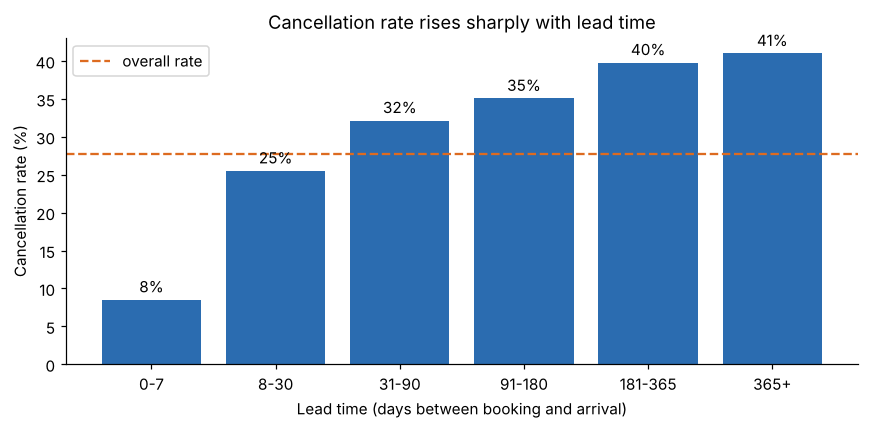

Median lead time - cancelled: 80.0 days | not cancelled: 38.0 days


In [29]:
# Lead time (Figure 1 in the report)
lead = df.groupby("lead_time_band", observed=True)["is_canceled"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(lead.index.astype(str), lead, color=BLUE)
for i, v in enumerate(lead):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.axhline(df["is_canceled"].mean() * 100, color=ORANGE, ls="--", label="overall rate")
ax.set_xlabel("Lead time (days between booking and arrival)"); ax.set_ylabel("Cancellation rate (%)")
ax.set_title("Cancellation rate rises sharply with lead time"); ax.legend()
plt.tight_layout(); plt.savefig("fig1_lead_time.png", dpi=150); plt.show()

print("Median lead time - cancelled:", df.loc[df.is_canceled == 1, "lead_time"].median(),
      "days | not cancelled:", df.loc[df.is_canceled == 0, "lead_time"].median(), "days")

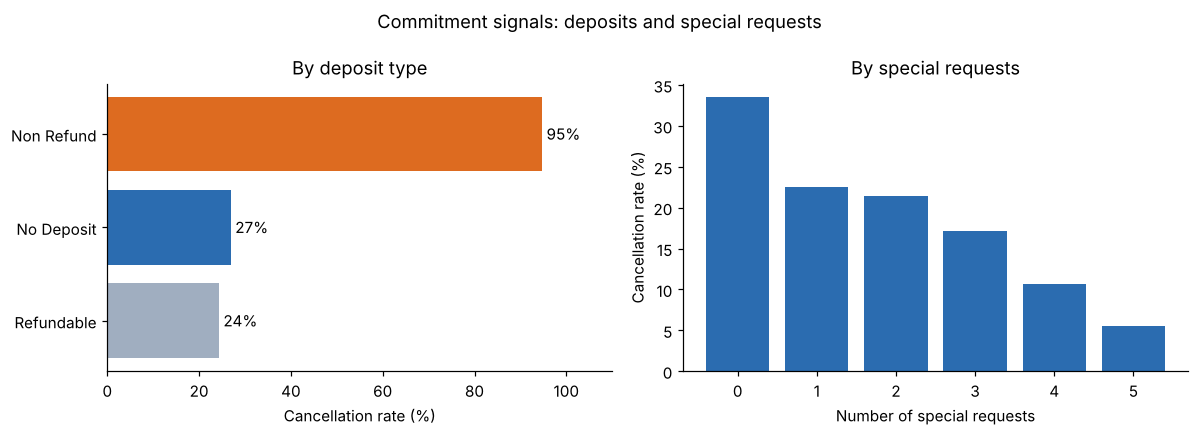

In [30]:
# Deposit type and special requests (Figure 2 in the report)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dep = df.groupby("deposit_type")["is_canceled"].mean().sort_values() * 100
axes[0].barh(dep.index, dep.values, color=[GREY, BLUE, ORANGE])
for i, v in enumerate(dep.values):
    axes[0].text(v + 1, i, f"{v:.0f}%", va="center")
axes[0].set_xlim(0, 110); axes[0].set_xlabel("Cancellation rate (%)"); axes[0].set_title("By deposit type")

req = df.groupby("total_of_special_requests")["is_canceled"].mean() * 100
axes[1].bar(req.index.astype(str), req.values, color=BLUE)
axes[1].set_xlabel("Number of special requests"); axes[1].set_ylabel("Cancellation rate (%)")
axes[1].set_title("By special requests")
plt.suptitle("Commitment signals: deposits and special requests")
plt.tight_layout(); plt.savefig("fig2_deposit_requests.png", dpi=150); plt.show()

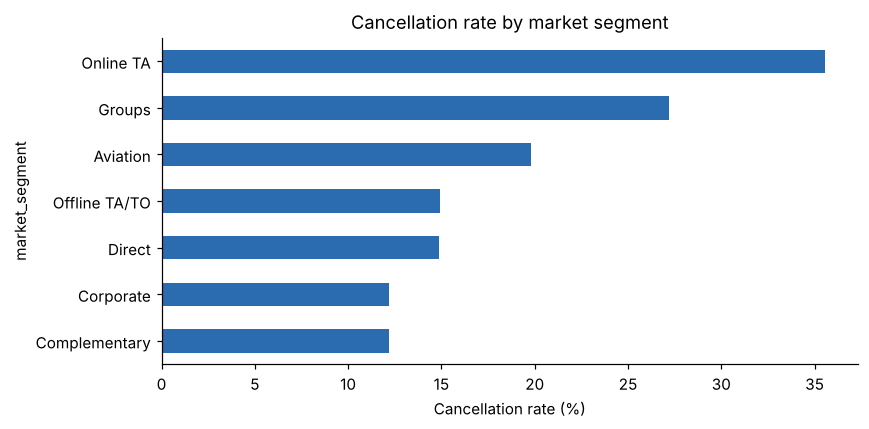

Parking requested : 0.0 %
No parking        : 30.2 %
Repeat guests     : 8.2 %
New guests        : 28.4 %


In [31]:
seg = (df.groupby("market_segment")["is_canceled"].mean() * 100).sort_values()
seg.plot(kind="barh", color=BLUE, figsize=(8, 4))
plt.xlabel("Cancellation rate (%)"); plt.title("Cancellation rate by market segment")
plt.tight_layout(); plt.show()

print("Parking requested :", round(df.loc[df.required_car_parking_spaces > 0, "is_canceled"].mean() * 100, 1), "%")
print("No parking        :", round(df.loc[df.required_car_parking_spaces == 0, "is_canceled"].mean() * 100, 1), "%")
print("Repeat guests     :", round(df.loc[df.is_repeated_guest == 1, "is_canceled"].mean() * 100, 1), "%")
print("New guests        :", round(df.loc[df.is_repeated_guest == 0, "is_canceled"].mean() * 100, 1), "%")

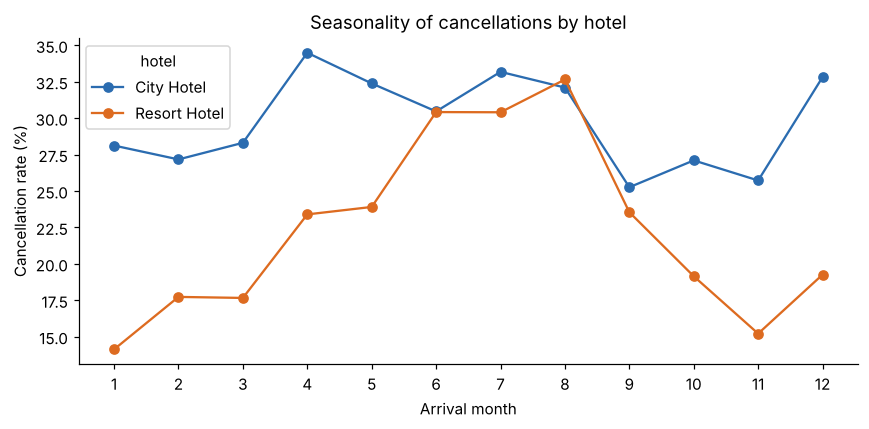

In [32]:
month = df.groupby(["arrival_month_num", "hotel"])["is_canceled"].mean().unstack() * 100
month.plot(marker="o", figsize=(8, 4), color=[BLUE, ORANGE])
plt.xticks(range(1, 13)); plt.xlabel("Arrival month"); plt.ylabel("Cancellation rate (%)")
plt.title("Seasonality of cancellations by hotel"); plt.tight_layout(); plt.show()

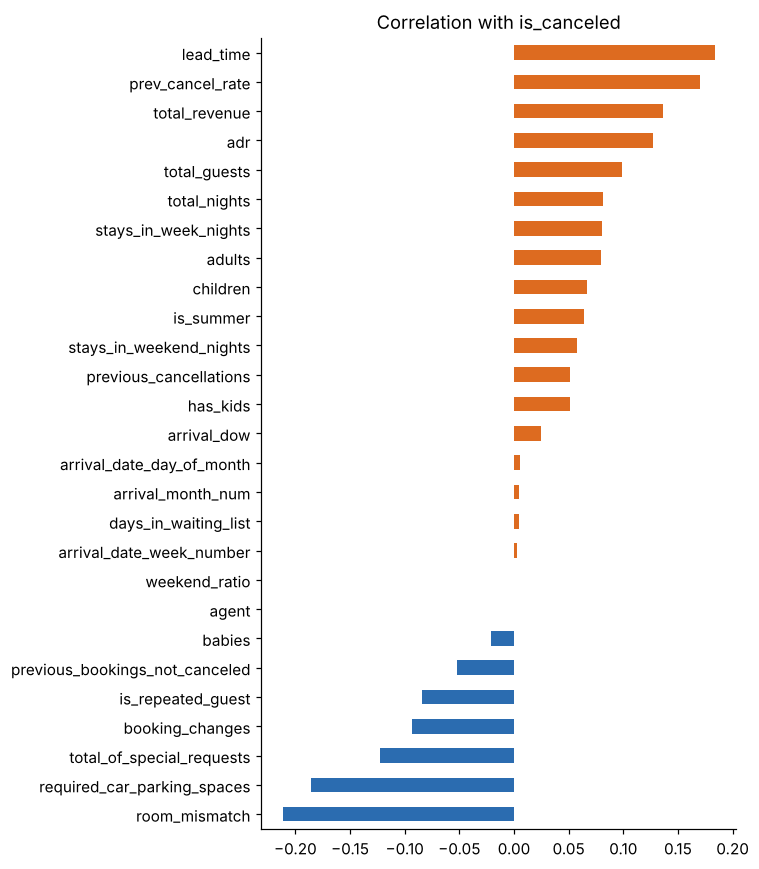

In [33]:
# Correlation analysis
corr = df.select_dtypes("number").drop(columns=["arrival_date_year"]).corr()["is_canceled"].drop("is_canceled").sort_values()
corr.plot(kind="barh", figsize=(7, 8), color=[ORANGE if v > 0 else BLUE for v in corr])
plt.title("Correlation with is_canceled"); plt.tight_layout(); plt.show()

In [34]:
# Part 4 – Modeling (Chapter 5)
# 4.1 Select attributes and set the label
num_features = ["lead_time", "arrival_month_num", "arrival_date_week_number", "arrival_date_day_of_month",
                "arrival_dow", "stays_in_weekend_nights", "stays_in_week_nights", "total_nights",
                "adults", "children", "babies", "total_guests", "has_kids", "is_repeated_guest",
                "previous_cancellations", "previous_bookings_not_canceled", "prev_cancel_rate",
                "booking_changes", "days_in_waiting_list", "adr", "total_revenue", "weekend_ratio",
                "required_car_parking_spaces", "total_of_special_requests", "is_summer"]
cat_features = ["hotel", "meal", "country_grp", "market_segment", "distribution_channel",
                "reserved_room_type", "deposit_type", "customer_type"]

X = df[num_features + cat_features]     # attributes
y = df["is_canceled"]                    # label
print("Attributes:", X.shape[1], "(", len(num_features), "numeric +", len(cat_features), "nominal ) | Label: is_canceled")

Attributes: 33 ( 25 numeric + 8 nominal ) | Label: is_canceled


In [35]:
# 4.2 Generate test design – split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)

print("Train:", len(X_tr), "| Validation:", len(X_val), "| Test (hold-out):", len(X_test))
print("Cancel rate - train %.3f  val %.3f  test %.3f" % (y_tr.mean(), y_val.mean(), y_test.mean()))

Train: 55440 | Validation: 13860 | Test (hold-out): 17325
Cancel rate - train 0.277  val 0.277  test 0.277


In [36]:
# 4.3 Preprocessing pipelines (Step 6 of Data Preparation, applied safely)
# For Logistic Regression and Naive Bayes: Z-normalization + one-hot (dummy) encoding
preprocess_linear = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)])

# For tree models: no scaling needed, categories -> integer codes
preprocess_tree = ColumnTransformer([
    ("num", "passthrough", num_features),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_features)])

def evaluate(model, X_, y_, threshold=0.5):
    """Performance (Binominal Classification): returns the metrics from Chapter 6."""
    proba = model.predict_proba(X_)[:, 1]
    pred  = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return {"accuracy":    accuracy_score(y_, pred),
            "precision":   precision_score(y_, pred, zero_division=0),
            "recall":      recall_score(y_, pred),
            "specificity": tn / (tn + fp),
            "f1":          f1_score(y_, pred),
            "AUC":         roc_auc_score(y_, proba)}

In [37]:
# 4.4 Select modeling techniques and build models
models = {
    "Baseline (majority class)": Pipeline([("pre", preprocess_linear), ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression":       Pipeline([("pre", preprocess_linear), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Naive Bayes":               Pipeline([("pre", preprocess_linear), ("model", GaussianNB())]),
    "Decision Tree":             Pipeline([("pre", preprocess_tree),   ("model", DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest":             Pipeline([("pre", preprocess_tree),   ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosted Trees":    Pipeline([("pre", preprocess_tree),   ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
}

val_results = {}
for name, model in models.items():
    model.fit(X_tr, y_tr)
    val_results[name] = evaluate(model, X_val, y_val)
    print("trained:", name)

pd.DataFrame(val_results).T.round(3).sort_values("f1", ascending=False)

trained: Baseline (majority class)
trained: Logistic Regression
trained: Naive Bayes
trained: Decision Tree
trained: Random Forest
trained: Gradient Boosted Trees


,accuracy,precision,recall,specificity,f1,AUC
Random Forest,0.822,0.661,0.731,0.857,0.695,0.887
Gradient Boosted Trees,0.795,0.593,0.829,0.782,0.691,0.890
Decision Tree,0.783,0.589,0.721,0.808,0.648,0.855
Logistic Regression,0.740,0.520,0.778,0.725,0.624,0.835
Naive Bayes,0.546,0.367,0.885,0.416,0.519,0.762
Baseline (majority class),0.723,0.000,0.000,1.000,0.000,0.500


In [38]:
# Cross-validation check
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    s = cross_val_score(models[name], X_train, y_train, cv=cv5, scoring="f1", n_jobs=-1)
    print(f"{name:22s} F1 = {s.mean():.3f} ± {s.std():.3f}")

Logistic Regression    F1 = 0.622 ± 0.005
Decision Tree          F1 = 0.638 ± 0.003
Random Forest          F1 = 0.692 ± 0.005


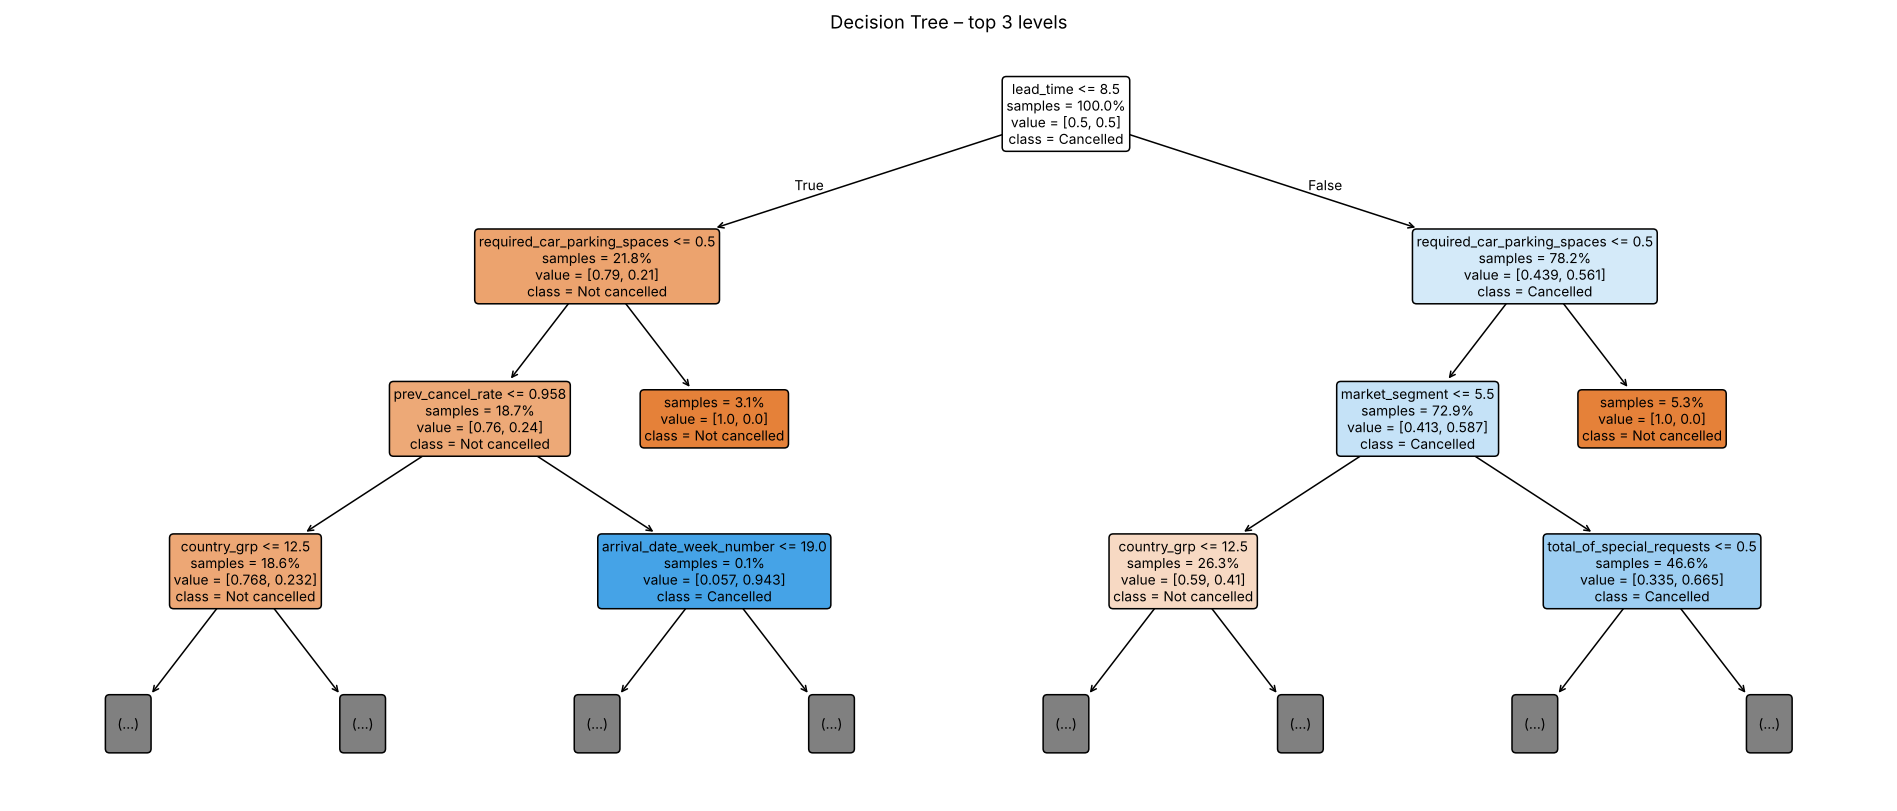

In [39]:
# Decision Tree – an interpretable model for managers
dt = models["Decision Tree"]
feature_names = num_features + cat_features            # order used by preprocess_tree
plt.figure(figsize=(22, 9))
plot_tree(dt.named_steps["model"], max_depth=3, feature_names=feature_names,
          class_names=["Not cancelled", "Cancelled"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Decision Tree – top 3 levels"); plt.show()

In [40]:
# 4.5 Optimize model parameters (hyperparameter tuning)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

dt_search = GridSearchCV(models["Decision Tree"],
                         {"model__max_depth": [6, 10, 14, 20], "model__min_samples_leaf": [1, 10, 50]},
                         scoring="f1", cv=cv, n_jobs=-1)
dt_search.fit(X_train, y_train)
print("Decision Tree best:", dt_search.best_params_, "| CV F1 = %.3f" % dt_search.best_score_)

Decision Tree best: {'model__max_depth': 14, 'model__min_samples_leaf': 50} | CV F1 = 0.648


In [41]:
rf_params = {"model__n_estimators":     [200, 300],
             "model__max_depth":        [None, 20, 30],
             "model__min_samples_leaf": [1, 2, 4],
             "model__max_features":     ["sqrt", 0.5]}
rf_search = RandomizedSearchCV(models["Random Forest"], rf_params, n_iter=5, scoring="f1",
                               cv=cv, n_jobs=1, random_state=RANDOM_STATE, verbose=1)
rf_search.fit(X_train, y_train)
print("Random Forest best:", rf_search.best_params_, "| CV F1 = %.3f" % rf_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Random Forest best: {'model__n_estimators': 300, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': 30} | CV F1 = 0.694


In [42]:
gbt_params = {"model__learning_rate":     [0.05, 0.1, 0.2],
              "model__max_iter":          [200, 400, 600],
              "model__max_leaf_nodes":    [31, 63, 127],
              "model__min_samples_leaf":  [20, 50],
              "model__l2_regularization": [0.0, 1.0]}
gbt_search = RandomizedSearchCV(models["Gradient Boosted Trees"], gbt_params, n_iter=10, scoring="f1",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1)
gbt_search.fit(X_train, y_train)
print("Gradient Boosted Trees best:", gbt_search.best_params_, "| CV F1 = %.3f" % gbt_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Gradient Boosted Trees best: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 127, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0} | CV F1 = 0.696


In [43]:
# Part 5 – Evaluation (Chapter 6)
# 5.1 Performance on the hold-out test set (Table 5 in the report)
for name in ["Baseline (majority class)", "Logistic Regression", "Naive Bayes"]:
    models[name].fit(X_train, y_train)

final_models = {
    "Baseline (majority class)":      models["Baseline (majority class)"],
    "Logistic Regression":            models["Logistic Regression"],
    "Naive Bayes":                    models["Naive Bayes"],
    "Decision Tree (tuned)":          dt_search.best_estimator_,
    "Random Forest (tuned)":          rf_search.best_estimator_,
    "Gradient Boosted Trees (tuned)": gbt_search.best_estimator_,
}
test_results = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in final_models.items()}).T
test_results.round(3).sort_values("f1", ascending=False)

,accuracy,precision,recall,specificity,f1,AUC
Random Forest (tuned),0.820,0.643,0.786,0.833,0.707,0.896
Gradient Boosted Trees (tuned),0.811,0.619,0.820,0.807,0.706,0.899
Decision Tree (tuned),0.762,0.546,0.824,0.737,0.657,0.865
Logistic Regression,0.743,0.525,0.768,0.734,0.623,0.832
Naive Bayes,0.555,0.371,0.874,0.432,0.521,0.761
Baseline (majority class),0.723,0.000,0.000,1.000,0.000,0.500


In [44]:
best_name  = test_results["f1"].idxmax()
best_model = final_models[best_name]
print("Final model (highest F1 on the test set):", best_name)
print()
print(classification_report(y_test, best_model.predict(X_test), target_names=["Not cancelled", "Cancelled"]))

Final model (highest F1 on the test set): Random Forest (tuned)

               precision    recall  f1-score   support

Not cancelled       0.91      0.83      0.87     12529
    Cancelled       0.64      0.79      0.71      4796

     accuracy                           0.82     17325
    macro avg       0.78      0.81      0.79     17325
 weighted avg       0.84      0.82      0.82     17325



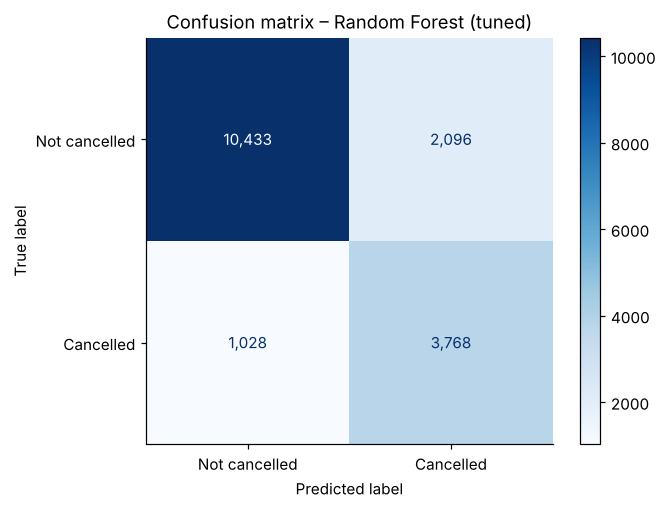

Caught 3,768 of 4,796 cancellations (recall 78.6%) | missed 1,028 | false alarms 2,096


In [45]:
# 5.2 Confusion matrix (Figure 3 in the report)
cm = confusion_matrix(y_test, best_model.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Not cancelled", "Cancelled"]).plot(cmap="Blues", values_format=",")
plt.title(f"Confusion matrix – {best_name}")
plt.savefig("fig3_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp:,} of {tp + fn:,} cancellations (recall {tp / (tp + fn):.1%}) | missed {fn:,} | false alarms {fp:,}")

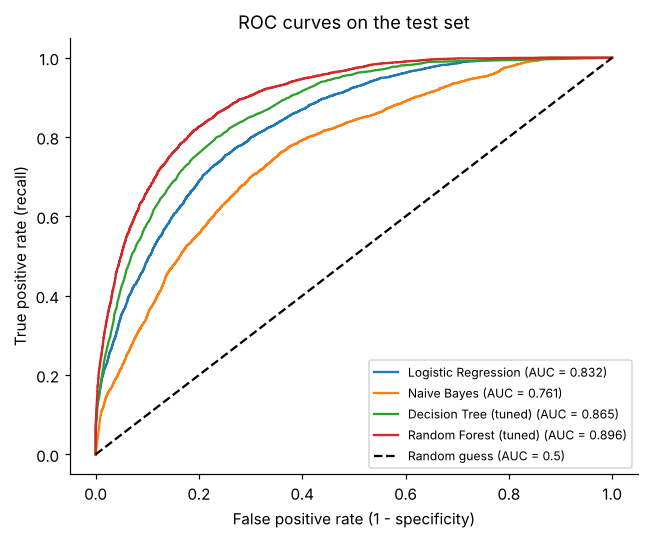

In [46]:
# 5.3 ROC curve and AUC
plt.figure(figsize=(6, 5))
for name in ["Logistic Regression", "Naive Bayes", "Decision Tree (tuned)", best_name]:
    proba = final_models[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig("fig_roc.png", dpi=150); plt.show()

        cancellations  bookings  cancel_rate_%  \
decile                                           
1                1506      1733           86.9   
2                1172      1733           67.6   
3                 840      1733           48.5   
4                 562      1733           32.4   
5                 352      1733           20.3   
6                 187      1733           10.8   
7                 125      1733            7.2   
8                  45      1733            2.6   
9                   7      1733            0.4   
10                  0      1728            0.0   

        cumulative_%_of_all_cancellations  lift  
decile                                           
1                                    31.4  3.14  
2                                    55.8  2.44  
3                                    73.4  1.75  
4                                    85.1  1.17  
5                                    92.4  0.73  
6                                    96.3  0.39  

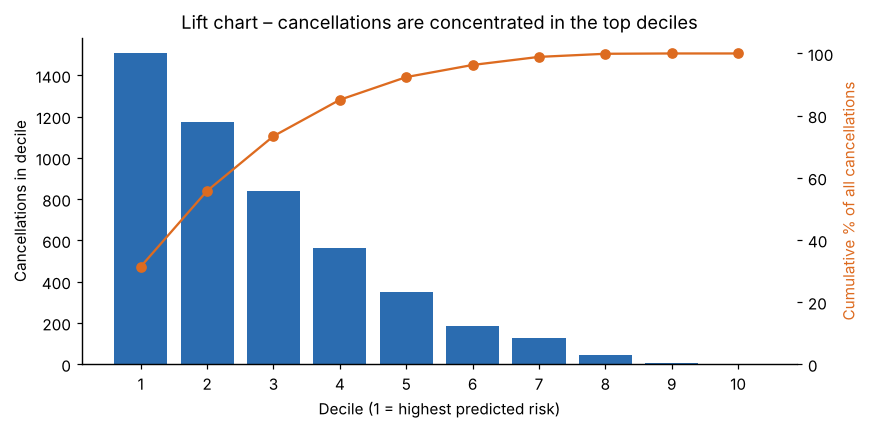

In [47]:
# 5.4 Lift chart
proba_best = best_model.predict_proba(X_test)[:, 1]
lift = pd.DataFrame({"actual": y_test.values, "proba": proba_best}).sort_values("proba", ascending=False)
lift["decile"] = np.repeat(np.arange(1, 11), int(np.ceil(len(lift) / 10)))[:len(lift)]
dec = lift.groupby("decile")["actual"].agg(cancellations="sum", bookings="count")
dec["cancel_rate_%"]   = (dec["cancellations"] / dec["bookings"] * 100).round(1)
dec["cumulative_%_of_all_cancellations"] = (dec["cancellations"].cumsum() / dec["cancellations"].sum() * 100).round(1)
dec["lift"] = (dec["cancellations"] / dec["bookings"] / y_test.mean()).round(2)
print(dec)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dec.index, dec["cancellations"], color=BLUE)
ax2 = ax.twinx(); ax2.plot(dec.index, dec["cumulative_%_of_all_cancellations"], color=ORANGE, marker="o")
ax.set_xlabel("Decile (1 = highest predicted risk)"); ax.set_ylabel("Cancellations in decile")
ax2.set_ylabel("Cumulative % of all cancellations", color=ORANGE); ax2.set_ylim(0, 105)
ax.set_xticks(range(1, 11)); plt.title("Lift chart – cancellations are concentrated in the top deciles")
plt.tight_layout(); plt.show()

In [48]:
# 5.5 Cost of errors – which mistake is more expensive?
COST_FN, COST_FP = 180, 20      # euros – business assumptions

def total_cost(model, threshold=0.5):
    pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return fn * COST_FN + fp * COST_FP, fn, fp

rows = {}
for name, m in final_models.items():
    cost, fn_, fp_ = total_cost(m)
    rows[name] = {"false negatives": fn_, "false positives": fp_, "total cost (€)": cost}
cost_table = pd.DataFrame(rows).T.sort_values("total cost (€)")
cost_table["saving vs baseline (€)"] = cost_table.loc["Baseline (majority class)", "total cost (€)"] - cost_table["total cost (€)"]
cost_table

,false negatives,false positives,total cost (€),saving vs baseline (€)
Gradient Boosted Trees (tuned),861,2421,203400,659880
Decision Tree (tuned),842,3290,217360,645920
Random Forest (tuned),1028,2096,226960,636320
Naive Bayes,603,7111,250760,612520
Logistic Regression,1115,3335,267400,595880
Baseline (majority class),4796,0,863280,0


In [49]:
# 5.6 Changing the threshold
thr_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    m = evaluate(best_model, X_test, y_test, threshold=t)
    cost, fn_, fp_ = total_cost(best_model, t)
    thr_rows.append({"threshold": t, "accuracy": m["accuracy"], "recall": m["recall"], "precision": m["precision"],
                     "false positives": fp_, "false negatives": fn_, "total cost (€)": cost})
thr = pd.DataFrame(thr_rows).set_index("threshold")
print(thr.round(3))
print("Lowest-cost threshold:", thr["total cost (€)"].idxmin())

           accuracy  recall  precision  false positives  false negatives  \
threshold                                                                  
0.3           0.728   0.927      0.505             4367              348   
0.4           0.785   0.868      0.573             3102              631   
0.5           0.820   0.786      0.643             2096             1028   
0.6           0.833   0.688      0.703             1396             1496   
0.7           0.833   0.575      0.765              846             2039   

           total cost (€)  
threshold                  
0.3                149980  
0.4                175620  
0.5                226960  
0.6                297200  
0.7                383940  
Lowest-cost threshold: 0.3


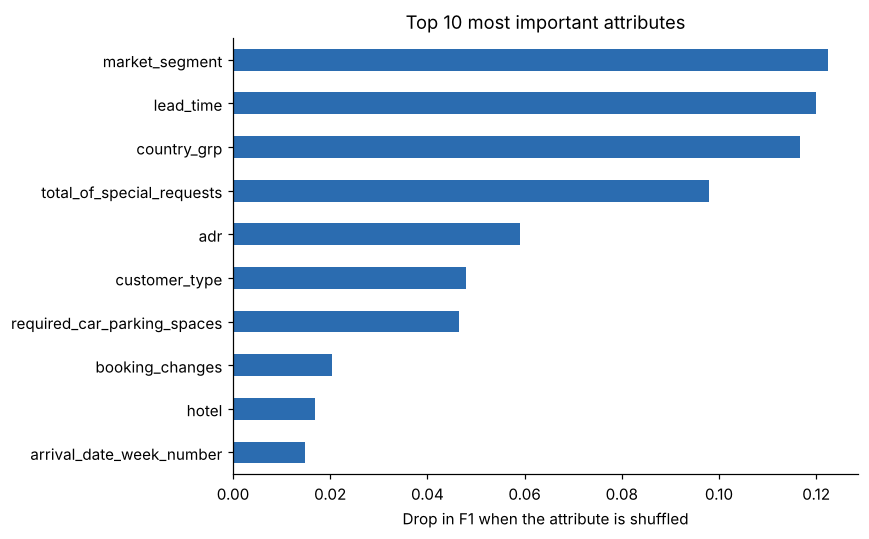

market_segment                 0.1225
lead_time                      0.1200
country_grp                    0.1166
total_of_special_requests      0.0979
adr                            0.0590
customer_type                  0.0479
required_car_parking_spaces    0.0465
booking_changes                0.0203
hotel                          0.0168
arrival_date_week_number       0.0148
dtype: float64

In [50]:
# 5.7 Which attributes drive the predictions?
sample = X_test.sample(5000, random_state=RANDOM_STATE)
perm = permutation_importance(best_model, sample, y_test.loc[sample.index],
                              n_repeats=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

importance.head(10)[::-1].plot(kind="barh", color=BLUE, figsize=(8, 5))
plt.xlabel("Drop in F1 when the attribute is shuffled"); plt.title("Top 10 most important attributes")
plt.tight_layout(); plt.savefig("fig3b_feature_importance.png", dpi=150); plt.show()
importance.head(10).round(4)

In [51]:
# 5.8 Go / No-Go decision for deployment
b = test_results.loc[best_name]
checks = pd.DataFrame({
    "criterion": ["F1 ≥ 0.70", "AUC ≥ 0.85 (good ranking)", "Recall ≥ 0.75 (catches most cancellations)",
                  "Beats the baseline", "Cheaper than doing nothing", "Uses only booking-time data (no leakage)"],
    "result":    [f"{b['f1']:.3f}", f"{b['AUC']:.3f}", f"{b['recall']:.3f}",
                  f"F1 {b['f1']:.3f} vs 0.000", f"saves €{cost_table.loc[best_name, 'saving vs baseline (€)']:,.0f} on the test set", "yes"],
    "pass":      [b["f1"] >= 0.70, b["AUC"] >= 0.85, b["recall"] >= 0.75, True,
                  cost_table.loc[best_name, "saving vs baseline (€)"] > 0, True]})
print(checks)
print("DECISION:", "GO ✅ - deploy the model" if checks["pass"].all() else "NO-GO ⚠️ - review the failed criteria")

                                    criterion                          result  \
0                                   F1 ≥ 0.70                           0.707   
1                   AUC ≥ 0.85 (good ranking)                           0.896   
2  Recall ≥ 0.75 (catches most cancellations)                           0.786   
3                          Beats the baseline               F1 0.707 vs 0.000   
4                  Cheaper than doing nothing  saves €636,320 on the test set   
5    Uses only booking-time data (no leakage)                             yes   

   pass  
0  True  
1  True  
2  True  
3  True  
4  True  
5  True  
DECISION: GO ✅ - deploy the model


In [52]:
# Part 6 – Deployment
joblib.dump({"model": best_model, "num": num_features, "cat": cat_features,
             "top_countries": list(top_countries)}, "model.joblib", compress=3)
print("Saved model.joblib")

try:                                   # in Colab: download the model and figures
    from google.colab import files
    files.download("model.joblib")
    for f in ["fig1_lead_time.png", "fig2_deposit_requests.png", "fig3_confusion_matrix.png",
              "fig3b_feature_importance.png", "fig_roc.png"]:
        files.download(f)
except ImportError:
    print("Not in Colab - model.joblib and the figures are saved in the current folder.")

Saved model.joblib
Not in Colab - model.joblib and the figures are saved in the current folder.


In [53]:
# Try it: predict one new booking
new_booking = {
    "hotel": "City Hotel", "lead_time": 200, "arrival_month_num": 8, "arrival_date_week_number": 33,
    "arrival_date_day_of_month": 15, "arrival_dow": 4, "stays_in_weekend_nights": 1, "stays_in_week_nights": 2,
    "adults": 2, "children": 0, "babies": 0, "meal": "BB", "country_grp": "PRT",
    "market_segment": "Online TA", "distribution_channel": "TA/TO", "is_repeated_guest": 0,
    "previous_cancellations": 0, "previous_bookings_not_canceled": 0, "reserved_room_type": "A",
    "booking_changes": 0, "deposit_type": "No Deposit", "days_in_waiting_list": 0,
    "customer_type": "Transient", "adr": 120.0, "required_car_parking_spaces": 0, "total_of_special_requests": 0,
}
b = new_booking
nights = b["stays_in_weekend_nights"] + b["stays_in_week_nights"]
b.update(total_nights=nights, total_guests=b["adults"] + b["children"] + b["babies"],
         has_kids=int(b["children"] + b["babies"] > 0), total_revenue=b["adr"] * nights,
         weekend_ratio=b["stays_in_weekend_nights"] / nights, is_summer=int(b["arrival_month_num"] in (6, 7, 8)),
         prev_cancel_rate=0.0)

p = best_model.predict_proba(pd.DataFrame([b])[num_features + cat_features])[0, 1]
level = "HIGH" if p >= 0.6 else "MEDIUM" if p >= 0.35 else "LOW"
print(f"Probability of cancellation: {p:.1%}  ->  {level} risk")
print(f"Revenue at risk: €{p * b['total_revenue']:,.0f}")

Probability of cancellation: 85.9%  ->  HIGH risk
Revenue at risk: €309


---
# Extra analysis
Run these after all the cells above.

### A. Choosing the final model with cross-validation
The model is chosen on cross-validation scores instead of the test set, so the test set is only used once, at the end.

In [54]:
# Choose the final model with cross-validation (not the test set)
cv_table = pd.DataFrame({
    "Decision Tree (tuned)":          [dt_search.best_score_],
    "Random Forest (tuned)":          [rf_search.best_score_],
    "Gradient Boosted Trees (tuned)": [gbt_search.best_score_],
}, index=["CV F1 (3-fold)"]).T
cv_table["Test F1"] = test_results.loc[cv_table.index, "f1"]
print(cv_table.round(3).sort_values("CV F1 (3-fold)", ascending=False))

                                CV F1 (3-fold)  Test F1
Gradient Boosted Trees (tuned)           0.696    0.706
Random Forest (tuned)                    0.694    0.707
Decision Tree (tuned)                    0.648    0.657


### B. Overfitting check
A large gap between training and test F1 means the model memorises the training data.

In [55]:
# Overfitting check: compare F1 on the training data and on the test data
rows = []
for name in ["Decision Tree (tuned)", "Random Forest (tuned)", "Gradient Boosted Trees (tuned)"]:
    m = final_models[name]
    rows.append({"model": name,
                 "train F1": f1_score(y_train, m.predict(X_train)),
                 "test F1":  f1_score(y_test,  m.predict(X_test))})
fit_check = pd.DataFrame(rows).set_index("model")
fit_check["gap"] = fit_check["train F1"] - fit_check["test F1"]
print(fit_check.round(3))

                                train F1  test F1    gap
model                                                   
Decision Tree (tuned)              0.674    0.657  0.017
Random Forest (tuned)              0.883    0.707  0.176
Gradient Boosted Trees (tuned)     0.774    0.706  0.068


### C. Precision–recall curve
Shows the trade-off behind the threshold choice.

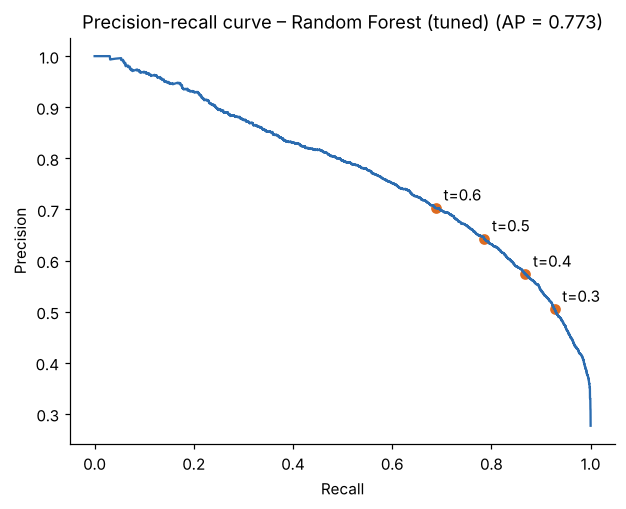

In [56]:
# Precision-recall curve: the trade-off behind the threshold choice
from sklearn.metrics import precision_recall_curve, average_precision_score
proba = best_model.predict_proba(X_test)[:, 1]
prec, rec, thr_pr = precision_recall_curve(y_test, proba)
plt.plot(rec, prec, color=BLUE)
for t in [0.3, 0.4, 0.5, 0.6]:
    i = (abs(thr_pr - t)).argmin()
    plt.scatter(rec[i], prec[i], color=ORANGE); plt.annotate(f"t={t}", (rec[i], prec[i]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-recall curve – {best_name} (AP = {average_precision_score(y_test, proba):.3f})")
plt.show()

### D. Final model at threshold 0.4

               precision    recall  f1-score   support

Not cancelled       0.94      0.75      0.83     12529
    Cancelled       0.57      0.87      0.69      4796

     accuracy                           0.78     17325
    macro avg       0.76      0.81      0.76     17325
 weighted avg       0.84      0.78      0.79     17325



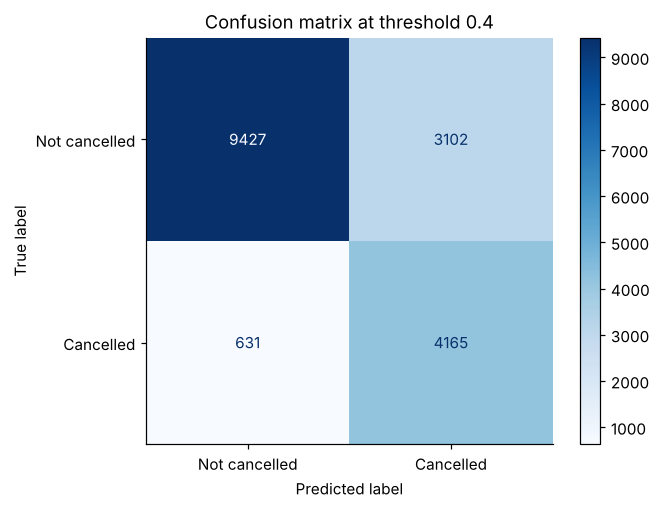

In [57]:
# Final model at the recommended threshold of 0.4
THRESHOLD = 0.4
pred_04 = (best_model.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_04, target_names=["Not cancelled", "Cancelled"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_04), display_labels=["Not cancelled", "Cancelled"]).plot(cmap="Blues")
plt.title(f"Confusion matrix at threshold {THRESHOLD}"); plt.show()

### E. Extra EDA

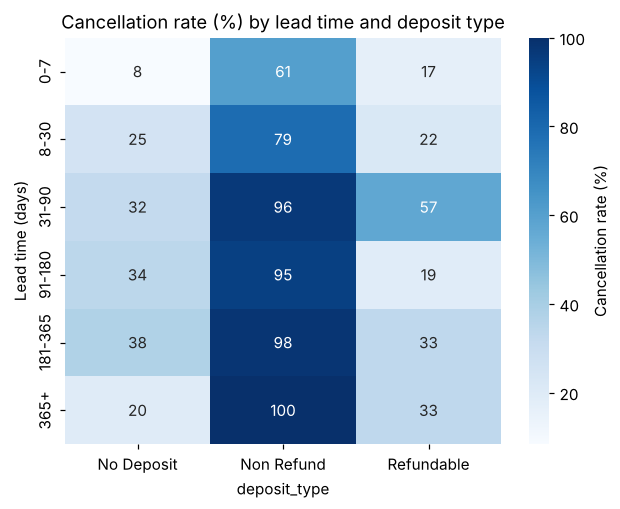

customer_type
Group               9.9
Transient-Party    15.3
Contract           16.4
Transient          30.3
Name: is_canceled, dtype: float64


In [58]:
# Extra EDA: cancellation rate (%) by lead time band and deposit type
heat = (df.pivot_table(index="lead_time_band", columns="deposit_type", values="is_canceled",
                       aggfunc="mean", observed=True) * 100)
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Cancellation rate (%)"})
plt.title("Cancellation rate (%) by lead time and deposit type"); plt.ylabel("Lead time (days)"); plt.show()

print((df.groupby("customer_type")["is_canceled"].mean() * 100).round(1).sort_values())

### F. Remaining data quality concern: the removed duplicates

In [59]:
# Remaining data quality concern: who are the removed duplicates?
dups = raw[raw.duplicated(keep=False)]
share = pd.DataFrame({
    "duplicates (%)": dups["market_segment"].value_counts(normalize=True) * 100,
    "all bookings (%)": raw["market_segment"].value_counts(normalize=True) * 100,
}).fillna(0).round(1).sort_values("duplicates (%)", ascending=False)
print(share)

                duplicates (%)  all bookings (%)
market_segment                                  
Groups                    41.6              16.6
Offline TA/TO             30.4              20.3
Online TA                 20.6              47.3
Corporate                  3.7               4.4
Direct                     3.5              10.6
Complementary              0.2               0.6
Aviation                   0.0               0.2
Undefined                  0.0               0.0
